# Día 5 — Modelos híbridos y contexto macroeconómico

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 10-11-2026 · **Unidades 3 y 4** · Contenidos 3.5, 4.1, 4.2 y 4.3 · **Actividad 3** (20 puntos)

Llevamos cuatro días con el mismo resultado: en el Test (2025–2026), **el promedio móvil de 12 meses es difícil de superar**. Ni el SARIMA ni el Random Forest lo lograron usando solo el pasado de la inflación.

Hoy probamos dos caminos para mejorar:

1. **Combinar modelos** (3.5): cada modelo se equivoca de forma distinta; juntos, los errores se compensan.
2. **Agregar información económica** (4.1–4.2): otras series del BCE pueden anticipar movimientos de la inflación.

Y cerramos con una pregunta que todo pronóstico económico debe hacerse (4.3): **¿la economía de los datos de entrenamiento es la misma que la que queremos pronosticar?**

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- qué es un **modelo híbrido** y dos formas de construirlo: el **promedio de pronósticos** y **ARIMA + Random Forest sobre los residuos**;
- cómo elegir **indicadores macroeconómicos** como predictores: transformarlos, rezagarlos y revisar su correlación;
- por qué algunas variables deben excluirse aunque estén muy correlacionadas;
- qué es un **cambio estructural**, cómo detectarlo y qué consecuencias tiene para elegir el periodo de entrenamiento;
- cómo comparar todos los modelos del módulo con las mismas métricas.

## Ruta del día

| Parte | Qué haremos |
|---|---|
| 1 | Datos y tabla de resultados acumulados |
| 2 | Híbrido 1: promedio de pronósticos |
| 3 | Híbrido 2: ARIMA + Random Forest sobre los residuos |
| 4 | Indicadores macroeconómicos: qué son y cómo prepararlos (4.1) |
| 5 | Selección de variables con correlaciones rezagadas (4.1) |
| 6 | Random Forest e híbrido con variables macro (4.2) |
| 7 | Cambios estructurales: dolarización, pandemia e IVA (4.3) |
| 8 | Comparación final, Actividad 3 y reto |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [ ]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib statsmodels scikit-learn

# 0. Librerías

No hay librerías nuevas: combinamos `ARIMA` (statsmodels) y `RandomForestRegressor` (scikit-learn). Usaremos también `OLS` de statsmodels, la regresión lineal "econométrica" que entrega errores estándar y p-valores.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from statsmodels.tsa.arima.model import ARIMA
import statsmodels.api as sm                      # OLS: regresión con inferencia estadística

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo5_econometria_forecasting_ia/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

In [4]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'Inflación: {len(y)} meses, {y.index.min():%b %Y} – {y.index.max():%b %Y}')
print('Indicadores disponibles:', series.columns.tolist())

Inflación: 260 meses, Jan 2005 – Aug 2026
Indicadores disponibles: ['ipc_indice', 'ipc_var_mensual', 'tasa_activa_ref_pct', 'tasa_pasiva_ref_pct', 'liquidez_m2_musd', 'reservas_internacionales_musd', 'exportaciones_fob_musd', 'exportaciones_petroleras_musd', 'importaciones_fob_musd', 'balanza_comercial_musd', 'riesgo_pais_pb', 'precio_crudo_oriente_usd', 'precio_wti_usd', 'salario_real_indice']


**Qué obtuvimos:** la inflación de siempre y las 14 columnas del archivo. Hoy usaremos varias de ellas como predictores.

## 1.1 Lo que sabemos hasta ahora (Test 2025 – agosto 2026, a un paso)

| Modelo | Día | MAE Test |
|---|---|---:|
| Promedio móvil 12 | 2 | 0.286 |
| ARIMA(1,0,0) | 3 | 0.307 |
| Random Forest (solo rezagos) | 4 | 0.313 |
| SARIMA(1,0,0)(1,0,0)₁₂ | 3 | 0.374 |
| Ingenuo | 1 | 0.478 |

Para comparar con justicia, hoy repetimos el mismo esquema:

- **Validación:** parámetros estimados con 2006–2014 y pronósticos a un paso en 2015–2024 (120 meses).
- **Test:** parámetros estimados con 2006–2024 y pronósticos a un paso en 2025 – agosto 2026 (20 meses).

In [5]:
REZAGOS = [1, 2, 3, 6, 12]

def tabla_variables(serie, extras=None):
    """Tabla del Día 4. `extras` es un DataFrame de predictores adicionales, ya rezagados."""
    tabla = pd.DataFrame({'objetivo': serie})
    for k in REZAGOS:
        tabla[f'rezago_{k}'] = serie.shift(k)
    tabla['media_3'] = serie.shift(1).rolling(3).mean()
    tabla['media_12'] = serie.shift(1).rolling(12).mean()
    tabla['mes'] = serie.index.month
    if extras is not None:
        tabla = tabla.join(extras)
    return tabla.dropna()

def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    return {'MAE': mean_absolute_error(real, pred), 'RMSE': np.sqrt(mean_squared_error(real, pred)),
            'Bias': np.mean(pred - real)}

PERIODOS = {
    'Validación': ('2014-12', '2015-01', '2024-12'),   # (estimar hasta, desde, hasta)
    'Test':       ('2024-12', '2025-01', '2026-08'),
}
PARAMETROS_RF = dict(n_estimators=100, max_depth=5, max_features=0.5, min_samples_leaf=1, random_state=42, n_jobs=-1)

tabla = tabla_variables(y)
X, objetivo = tabla.drop(columns='objetivo'), tabla['objetivo']
print('Tabla base:', X.shape)

Tabla base: (248, 8)


**Qué hicimos:** recuperamos la función `tabla_variables` del Día 4 (ahora acepta columnas extra) y los hiperparámetros elegidos por `GridSearchCV` ese día. `PERIODOS` guarda las fechas de cada evaluación para no repetirlas.

# 2. Híbrido 1: el promedio de pronósticos (3.5)

## 2.1 La idea

Si dos personas estiman el peso de una vaca y una se pasa 20 kg mientras la otra se queda corta 10 kg, el promedio de ambas se equivoca solo 5 kg. **Promediar pronósticos funciona cuando sus errores no van siempre en la misma dirección.**

$$
\hat y^{\text{promedio}}_t = \frac{1}{M}\sum_{m=1}^{M} \hat y^{(m)}_t
$$

### A mano

Tres modelos pronostican marzo de 2025 (real: 0.35):

| Modelo | Pronóstico | Error |
|---|---:|---:|
| ARIMA(1,0,0) | 0.16 | 0.19 |
| Random Forest | 0.15 | 0.20 |
| Promedio móvil 12 | 0.02 | 0.33 |
| **Promedio de los tres** | (0.16 + 0.15 + 0.02) / 3 = **0.11** | **0.24** |

En este mes el promedio no supera al mejor modelo, pero tampoco es el peor: **reduce el riesgo de elegir mal**. A lo largo de muchos meses suele quedar entre los mejores.

## 2.2 Las tres piezas

**Qué vamos a hacer:** escribir una función que devuelva los pronósticos a un paso de ARIMA, Random Forest y promedio móvil para un periodo.

In [6]:
def pronosticos_base(X, objetivo, estimar_hasta, desde, hasta):
    """Pronósticos a un paso de los tres modelos base en [desde, hasta], estimados hasta `estimar_hasta`."""
    # 1. ARIMA(1,0,0): estimado hasta estimar_hasta y aplicado a toda la serie.
    arima = ARIMA(y.loc[:estimar_hasta], order=(1, 0, 0), trend='c').fit()
    arima_pred = arima.apply(y).predict(start=desde, end=hasta)

    # 2. Random Forest con la tabla de variables.
    rf = RandomForestRegressor(**PARAMETROS_RF).fit(X.loc[:estimar_hasta], objetivo.loc[:estimar_hasta])
    rf_pred = pd.Series(rf.predict(X.loc[desde:hasta]), index=X.loc[desde:hasta].index)

    # 3. Promedio móvil de 12: ya está en la tabla.
    pm_pred = X.loc[desde:hasta, 'media_12']

    return pd.DataFrame({'ARIMA(1,0,0)': arima_pred, 'Random Forest': rf_pred, 'Promedio móvil 12': pm_pred})

pred_test = pronosticos_base(X, objetivo, *PERIODOS['Test'])
pred_test.loc['2025-03-01'].round(2)

ARIMA(1,0,0)         0.16
Random Forest        0.15
Promedio móvil 12    0.02
Name: 2025-03-01 00:00:00, dtype: float64

**Qué obtuvimos:** los tres pronósticos de marzo de 2025, los mismos del ejemplo a mano.

## 2.3 Promedios y evaluación

Probamos dos combinaciones: los tres modelos, y solo ARIMA con promedio móvil (los dos mejores del Test anterior).

In [7]:
def agregar_promedios(pred):
    pred = pred.copy()
    pred['Promedio de los 3'] = pred[['ARIMA(1,0,0)', 'Random Forest', 'Promedio móvil 12']].mean(axis=1)
    pred['Promedio ARIMA + PM12'] = pred[['ARIMA(1,0,0)', 'Promedio móvil 12']].mean(axis=1)
    return pred

resultados = {}
for periodo, fechas in PERIODOS.items():
    pred = agregar_promedios(pronosticos_base(X, objetivo, *fechas))
    real = objetivo.loc[fechas[1]:fechas[2]]
    resultados[periodo] = pd.DataFrame({m: metricas(real, pred[m]) for m in pred}).T['MAE']

tabla_promedios = pd.DataFrame(resultados)
tabla_promedios.sort_values('Validación').round(3)

,Validación,Test
Promedio móvil 12,0.248,0.286
Promedio ARIMA + PM12,0.250,0.287
Promedio de los 3,0.255,0.284
"ARIMA(1,0,0)",0.276,0.307
Random Forest,0.280,0.313


### Lectura

- En **Validación**, el promedio móvil sigue siendo el mejor modelo individual (≈ 0.25), y los dos promedios quedan **muy cerca** (≈ 0.25).
- En **Test**, el **promedio de los 3** (≈ 0.284) queda primero, apenas por delante del promedio móvil (≈ 0.286).
- **Ningún promedio es el peor** en ningún periodo: combinar protege contra elegir el modelo equivocado.

### ¿Por qué funciona tan poco aquí?

Porque los errores de los tres modelos están **muy correlacionados**: todos fallan en los mismos meses de choque (2024).

In [8]:
errores_test = pred_test.sub(objetivo.loc['2025-01':'2026-08'], axis=0)
errores_test.corr().round(2)

,"ARIMA(1,0,0)",Random Forest,Promedio móvil 12
"ARIMA(1,0,0)",1.00,0.88,0.90
Random Forest,0.88,1.00,0.95
Promedio móvil 12,0.90,0.95,1.00


Correlaciones de los errores de ≈ 0.9: cuando uno se equivoca hacia arriba, los otros también. **Un promedio ayuda mucho cuando los modelos son distintos y poco cuando se parecen.** Para diversificar hace falta información distinta (parte 6).

# 3. Híbrido 2: ARIMA + Random Forest sobre los residuos (3.5)

## 3.1 La idea

Cada modelo es bueno en algo distinto:

- **ARIMA** captura bien la dinámica **lineal** (persistencia y estacionalidad), pero no relaciones no lineales.
- **Random Forest** captura relaciones **no lineales** e interacciones, pero no extrapola tendencias.

El híbrido los usa **en secuencia**:

| Paso | Qué se hace | Resultado |
|---:|---|---|
| 1 | Estimar ARIMA | pronóstico lineal $\hat y^{\text{ARIMA}}_t$ |
| 2 | Calcular sus residuos en Train | $e_t = y_t - \hat y^{\text{ARIMA}}_t$: lo que ARIMA **no** explicó |
| 3 | Entrenar Random Forest para predecir $e_t$ | el RF busca patrones en lo que sobró |
| 4 | Pronóstico final | $\hat y_t = \hat y^{\text{ARIMA}}_t + \hat e^{\text{RF}}_t$ |

**Si los residuos de ARIMA son ruido puro, el RF no encontrará nada** y su corrección será cercana a cero. Si hay algún patrón no lineal, el RF lo aprovecha.

### A mano, para un mes

| Pieza | Valor |
|---|---:|
| Pronóstico ARIMA | 0.24 |
| Corrección del RF (residuo pronosticado) | −0.05 |
| **Pronóstico híbrido** | 0.24 + (−0.05) = **0.19** |

## 3.2 Implementación

In [9]:
def hibrido_residuos(X, objetivo, estimar_hasta, desde, hasta):
    """ARIMA(1,0,0) + Random Forest entrenado sobre los residuos a un paso de ARIMA."""
    # Paso 1: ARIMA con parámetros estimados hasta estimar_hasta.
    arima = ARIMA(y.loc[:estimar_hasta], order=(1, 0, 0), trend='c').fit()
    arima_aplicado = arima.apply(y)

    # Paso 2: residuos a un paso de ARIMA (real menos ajustado), en las fechas de la tabla.
    residuos = (y - arima_aplicado.fittedvalues).loc[X.index]

    # Paso 3: Random Forest que aprende a predecir el residuo, solo con datos hasta estimar_hasta.
    rf_residuo = RandomForestRegressor(**PARAMETROS_RF).fit(X.loc[:estimar_hasta], residuos.loc[:estimar_hasta])

    # Paso 4: pronóstico ARIMA + corrección.
    arima_pred = arima_aplicado.predict(start=desde, end=hasta)
    correccion = pd.Series(rf_residuo.predict(X.loc[desde:hasta]), index=X.loc[desde:hasta].index)
    return arima_pred + correccion, correccion

hibrido_test, correccion_test = hibrido_residuos(X, objetivo, *PERIODOS['Test'])

print('Corrección media del RF:', round(correccion_test.mean(), 3))
print('Corrección máxima (valor absoluto):', round(correccion_test.abs().max(), 3))

Corrección media del RF: -0.063
Corrección máxima (valor absoluto): 0.604


**Qué obtuvimos:** en promedio, el Random Forest corrige a ARIMA ≈ −0.06 puntos (lo baja un poco), y en algún mes la corrección llega a ≈ 0.6. Es decir, sí encuentra algo de patrón en lo que ARIMA dejó sin explicar.

In [10]:
for periodo, fechas in PERIODOS.items():
    hib, _ = hibrido_residuos(X, objetivo, *fechas)
    tabla_promedios.loc['Híbrido ARIMA + RF residuos', periodo] = mean_absolute_error(objetivo.loc[fechas[1]:fechas[2]], hib)

tabla_promedios.sort_values('Test').round(3)

,Validación,Test
Promedio de los 3,0.255,0.284
Promedio móvil 12,0.248,0.286
Promedio ARIMA + PM12,0.250,0.287
Híbrido ARIMA + RF residuos,0.268,0.292
"ARIMA(1,0,0)",0.276,0.307
Random Forest,0.280,0.313


### Lectura

El híbrido de residuos **mejora a ARIMA solo** en ambos periodos (Validación ≈ 0.268 frente a 0.276; Test ≈ 0.292 frente a 0.307): el RF sí encuentra algo de patrón en lo que ARIMA dejó. Pero no supera al promedio móvil.

**Conclusión de las partes 2 y 3:** con **la misma información** (el pasado de la inflación), cambiar o combinar modelos mueve el error en centésimas. Para mejorar de verdad necesitamos **información nueva**.

# 4. Indicadores macroeconómicos (4.1)

## 4.1 ¿Qué información económica podría anticipar la inflación?

La teoría económica sugiere varios canales. Para cada uno buscamos un indicador en los datos del BCE:

| Canal | Idea | Indicador en `series_economicas.csv` |
|---|---|---|
| **Dinero** | más liquidez puede presionar precios | `liquidez_m2_musd` (M2) |
| **Costos importados** | el Ecuador importa bienes de consumo e insumos | `importaciones_fob_musd` |
| **Petróleo** | afecta combustibles, transporte e ingresos del país | `precio_crudo_oriente_usd`, `precio_wti_usd` |
| **Demanda externa** | más exportaciones → más ingresos → más demanda | `exportaciones_fob_musd` |
| **Riesgo y financiamiento** | condiciones financieras del país | `riesgo_pais_pb` |
| **Reservas** | liquidez externa de la economía dolarizada | `reservas_internacionales_musd` |

## 4.2 Preparar cada indicador: tres reglas

**Regla 1 · Transformar a una escala comparable y estacionaria.** Las exportaciones en millones de dólares crecen con los años (no estacionarias, Día 2). Lo que interesa es **cuánto cambian**:

| Indicador | Transformación | Por qué |
|---|---|---|
| M2, exportaciones, importaciones, reservas | **variación anual** (%): `pct_change(12) * 100` | elimina tendencia y estacionalidad |
| precios del petróleo, riesgo país | **variación mensual** (%): `pct_change() * 100` | son precios de mercado que cambian mes a mes |

**Regla 2 · Rezagar.** Para pronosticar la inflación de marzo solo podemos usar indicadores **conocidos a fines de febrero** o antes. Además, el BCE publica algunos indicadores con semanas de retraso. Usaremos siempre **al menos un mes de rezago** (`shift(1)` o más).

**Regla 3 · Evitar variables que contienen la respuesta.** El **salario real** se calcula dividiendo el salario nominal por el IPC: si la inflación sube, el salario real baja **por construcción**. Su correlación con la inflación es en parte mecánica, no una relación que ayude a anticipar. **La excluimos**, igual que en el Módulo 3 excluíamos `duration` en Bank Marketing.

**Qué vamos a hacer:** crear la tabla de indicadores transformados.

In [11]:
indicadores = pd.DataFrame({
    'm2_var_anual':        series['liquidez_m2_musd'].pct_change(12) * 100,
    'export_var_anual':    series['exportaciones_fob_musd'].pct_change(12) * 100,
    'import_var_anual':    series['importaciones_fob_musd'].pct_change(12) * 100,
    'reservas_var_anual':  series['reservas_internacionales_musd'].pct_change(12) * 100,
    'crudo_var_mensual':   series['precio_crudo_oriente_usd'].pct_change() * 100,
    'wti_var_mensual':     series['precio_wti_usd'].pct_change() * 100,
    'riesgo_var_mensual':  series['riesgo_pais_pb'].pct_change() * 100,
})

indicadores.loc['2005':].describe().T[['count', 'mean', 'std', 'min', 'max']].round(1)

,count,mean,std,min,max
m2_var_anual,260.0,12.7,5.6,-1.1,25.4
export_var_anual,260.0,10.5,23.9,-50.5,101.9
import_var_anual,260.0,9.9,23.3,-42.9,77.0
reservas_var_anual,261.0,16.5,38.0,-56.2,190.4
crudo_var_mensual,260.0,1.1,11.8,-45.6,61.3
wti_var_mensual,260.0,0.8,10.6,-44.7,72.9
riesgo_var_mensual,261.0,1.2,20.1,-49.2,205.0


### Cómo leer la tabla

- `count`: meses disponibles desde 2005 (algunos indicadores llegan hasta agosto de 2026 y otros hasta septiembre).
- La **M2** creció en promedio ≈ 13 % al año; las **exportaciones** ≈ 10 %, con mucha más variación (desviación ≈ 24 puntos).
- Los precios del **petróleo** y el **riesgo país** tienen desviaciones grandes: varían mucho de un mes a otro.

Todos están ahora en porcentajes, una escala comparable entre sí.

# 5. Selección de variables: correlaciones rezagadas (4.1)

## 5.1 La idea

Para cada indicador $x$ y cada rezago $k$ calculamos la correlación entre la inflación de hoy y el indicador de hace $k$ meses:

$$
\rho_k = \text{corr}(y_t,\; x_{t-k})
$$

Esto se llama **correlación cruzada**. Si es alta para algún $k$, el indicador **anticipa** la inflación con $k$ meses de ventaja.

**Importante:** usamos solo datos **hasta 2024** para elegir. Si eligiéramos mirando 2025–2026, estaríamos usando el Test para decidir.

**Qué vamos a hacer:** calcular la correlación de cada indicador con la inflación para rezagos de 1, 2, 3, 6 y 12 meses.

In [12]:
y_hasta_2024 = y.loc[:'2024-12']

correlaciones = pd.DataFrame({
    f'rezago_{k}': {col: y_hasta_2024.corr(indicadores[col].shift(k)) for col in indicadores}
    for k in [1, 2, 3, 6, 12]
})

correlaciones.round(2)

,rezago_1,rezago_2,rezago_3,rezago_6,rezago_12
m2_var_anual,0.30,0.29,0.28,0.23,0.20
export_var_anual,0.24,0.23,0.23,0.13,0.11
import_var_anual,0.18,0.18,0.21,0.19,0.16
reservas_var_anual,0.15,0.11,0.11,0.10,0.08
crudo_var_mensual,-0.01,-0.08,0.01,0.09,0.16
wti_var_mensual,-0.05,-0.06,0.03,0.09,0.10
riesgo_var_mensual,0.08,-0.01,-0.08,-0.03,-0.02


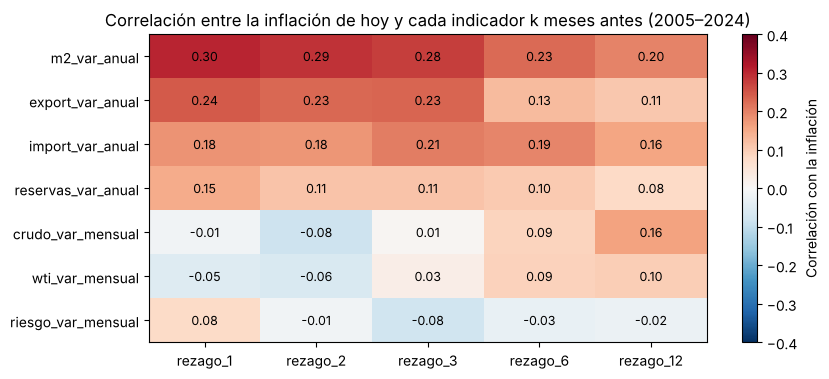

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(correlaciones.values, cmap='RdBu_r', vmin=-0.4, vmax=0.4, aspect='auto')
ax.set_xticks(range(correlaciones.shape[1]), correlaciones.columns)
ax.set_yticks(range(correlaciones.shape[0]), correlaciones.index)
for i in range(correlaciones.shape[0]):
    for j in range(correlaciones.shape[1]):
        ax.text(j, i, f'{correlaciones.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, label='Correlación con la inflación')
ax.set_title('Correlación entre la inflación de hoy y cada indicador k meses antes (2005–2024)')
plt.show()

### Lectura

| Indicador | Mejor rezago | Correlación | Lectura |
|---|---|---:|---|
| M2 (variación anual) | 1 | ≈ 0.30 | más liquidez anticipa algo más de inflación |
| Exportaciones (variación anual) | 1–3 | ≈ 0.23–0.25 | más ingresos externos, más demanda |
| Importaciones (variación anual) | 3 | ≈ 0.21 | |
| Reservas (variación anual) | 1 | ≈ 0.15 | señal débil |
| Precio del crudo (variación mensual) | 12 | ≈ 0.16 | el efecto del petróleo tarda en llegar a precios |
| WTI y riesgo país (variación mensual) | — | < 0.10 | sin señal clara |

Todas las correlaciones son **moderadas o débiles** (ninguna pasa de 0.31), y recordemos que $r_1$ de la propia inflación era 0.37. Ningún indicador por sí solo explica mucho, pero varios juntos pueden aportar.

**Selección:** usamos los cuatro con señal más clara, cada uno en su mejor rezago:

| Variable | Rezago |
|---|---:|
| `m2_var_anual` | 1 |
| `export_var_anual` | 1 |
| `import_var_anual` | 3 |
| `crudo_var_mensual` | 12 |

> **Cuidado con la correlación:** que la M2 de hace un mes se correlacione con la inflación no prueba que la cause. Puede haber un tercer factor (por ejemplo, el ciclo de precios del petróleo) que mueve a ambas. Para pronosticar basta con que la relación sea **estable**; para hacer política económica haría falta más.

In [14]:
seleccion = {'m2_var_anual': 1, 'export_var_anual': 1, 'import_var_anual': 3, 'crudo_var_mensual': 12}

extras = pd.DataFrame({f'{col}_t{k}': indicadores[col].shift(k) for col, k in seleccion.items()})

tabla_macro = tabla_variables(y, extras)
X_macro, objetivo_macro = tabla_macro.drop(columns='objetivo'), tabla_macro['objetivo']

print('Tabla con variables macro:', X_macro.shape)
print('Columnas nuevas:', [c for c in X_macro.columns if c not in X.columns])
tabla_macro.loc[['2025-03-01']].round(2).T

Tabla con variables macro: (248, 12)
Columnas nuevas: ['m2_var_anual_t1', 'export_var_anual_t1', 'import_var_anual_t3', 'crudo_var_mensual_t12']


fecha,2025-03-01
objetivo,0.35
rezago_1,0.09
rezago_2,-0.15
rezago_3,-0.99
rezago_6,0.18
rezago_12,0.29
media_3,-0.35
media_12,0.02
mes,3.00
m2_var_anual_t1,12.17


**Qué obtuvimos:** la misma tabla de 248 filas del Día 4 con cuatro columnas nuevas. En la fila de marzo de 2025, por ejemplo, `m2_var_anual_t1` es el crecimiento anual de la M2 **en febrero de 2025** y `crudo_var_mensual_t12` es la variación del crudo **en marzo de 2024**.

# 6. Random Forest e híbrido con variables macro (4.2)

## 6.1 Validación temporal

**Qué vamos a hacer:** comparar el Random Forest con y sin variables macro, con `TimeSeriesSplit` (Día 4) sobre 2006–2024.

In [15]:
tscv = TimeSeriesSplit(n_splits=5)

def mae_cv(Xc, yc):
    return -cross_val_score(RandomForestRegressor(**PARAMETROS_RF), Xc.loc[:'2024-12'], yc.loc[:'2024-12'],
                            cv=tscv, scoring='neg_mean_absolute_error').mean()

print('MAE validación · RF solo rezagos:   ', round(mae_cv(X, objetivo), 3))
print('MAE validación · RF + variables macro:', round(mae_cv(X_macro, objetivo_macro), 3))

MAE validación · RF solo rezagos:    0.239


MAE validación · RF + variables macro: 0.242


**Lectura:** en validación temporal, agregar las variables macro **no mejora** (≈ 0.239 frente a ≈ 0.242). Es un resultado honesto: con correlaciones de 0.2–0.3, la información nueva es poca y el modelo tiene más columnas en las que equivocarse.

## 6.2 Test: una sola vez

Aun así, evaluamos en el Test los modelos con variables macro, ya fijados.

In [16]:
for periodo, fechas in PERIODOS.items():
    pred_m = pronosticos_base(X_macro, objetivo_macro, *fechas)
    real = objetivo_macro.loc[fechas[1]:fechas[2]]
    tabla_promedios.loc['RF + macro', periodo] = mean_absolute_error(real, pred_m['Random Forest'])
    pred_m = agregar_promedios(pred_m)
    tabla_promedios.loc['Promedio de los 3 (con RF + macro)', periodo] = mean_absolute_error(real, pred_m['Promedio de los 3'])
    hib_m, _ = hibrido_residuos(X_macro, objetivo_macro, *fechas)
    tabla_promedios.loc['Híbrido ARIMA + RF residuos (macro)', periodo] = mean_absolute_error(real, hib_m)

tabla_promedios.sort_values('Test').round(3)

,Validación,Test
RF + macro,0.272,0.272
Promedio de los 3 (con RF + macro),0.252,0.280
Promedio de los 3,0.255,0.284
Promedio móvil 12,0.248,0.286
Promedio ARIMA + PM12,0.250,0.287
Híbrido ARIMA + RF residuos,0.268,0.292
Híbrido ARIMA + RF residuos (macro),0.257,0.295
"ARIMA(1,0,0)",0.276,0.307
Random Forest,0.280,0.313


### Lectura

- **RF + macro** obtiene el **menor MAE en el Test** de todo el módulo (≈ 0.272), por debajo del promedio móvil (≈ 0.286).
- El **promedio de los 3 con RF + macro** queda segundo (≈ 0.280).
- Pero en **Validación**, RF + macro (≈ 0.272) sigue por detrás del promedio móvil (≈ 0.248).

**¿Cómo interpretarlo?** Con 20 meses de Test, una diferencia de 0.014 puede deberse al azar. Y la validación de 10 años no la confirmó. **No podemos afirmar que las variables macro mejoren el pronóstico**; sí podemos decir que en 2025–2026 ayudaron. Es exactamente el tipo de resultado que hay que reportar con sus límites (Día 6).

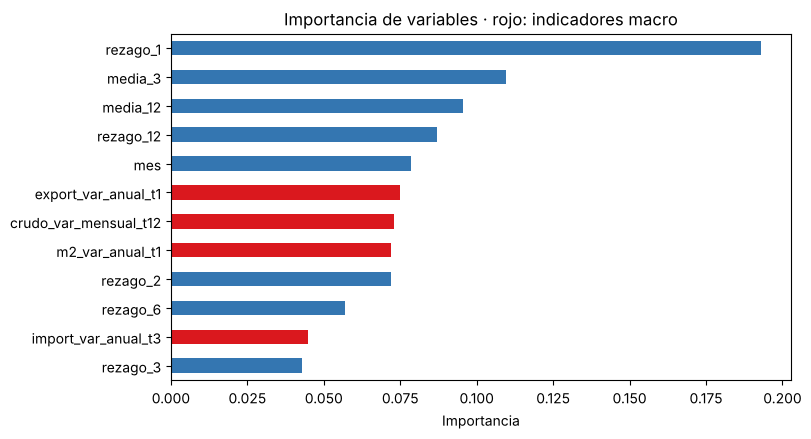

Importancia total de las variables macro: 0.264


In [17]:
rf_macro = RandomForestRegressor(**PARAMETROS_RF).fit(X_macro.loc[:'2024-12'], objetivo_macro.loc[:'2024-12'])
importancia = pd.Series(rf_macro.feature_importances_, index=X_macro.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ['#DA181E' if c in extras.columns else '#3476B1' for c in importancia.index]
importancia.plot.barh(ax=ax, color=colores)
ax.set_xlabel('Importancia')
ax.set_title('Importancia de variables · rojo: indicadores macro')
plt.show()

print('Importancia total de las variables macro:', round(importancia[extras.columns].sum(), 3))

**Lectura:** las cuatro variables macro suman ≈ 0.26 de la importancia total. Ninguna supera al `rezago_1`, pero la variación anual de las exportaciones, el crudo con 12 meses de rezago y la M2 se ubican al nivel de los rezagos de la propia inflación. El modelo **sí las usa**, aunque eso no garantiza que mejoren el pronóstico fuera de muestra.

# 7. Series oficiales en contexto (4.2)

Antes de hablar de cambios estructurales, miremos juntas las series principales del BCE desde 2005. **Qué vamos a hacer:** un panel con cinco indicadores y las fechas de tres eventos.

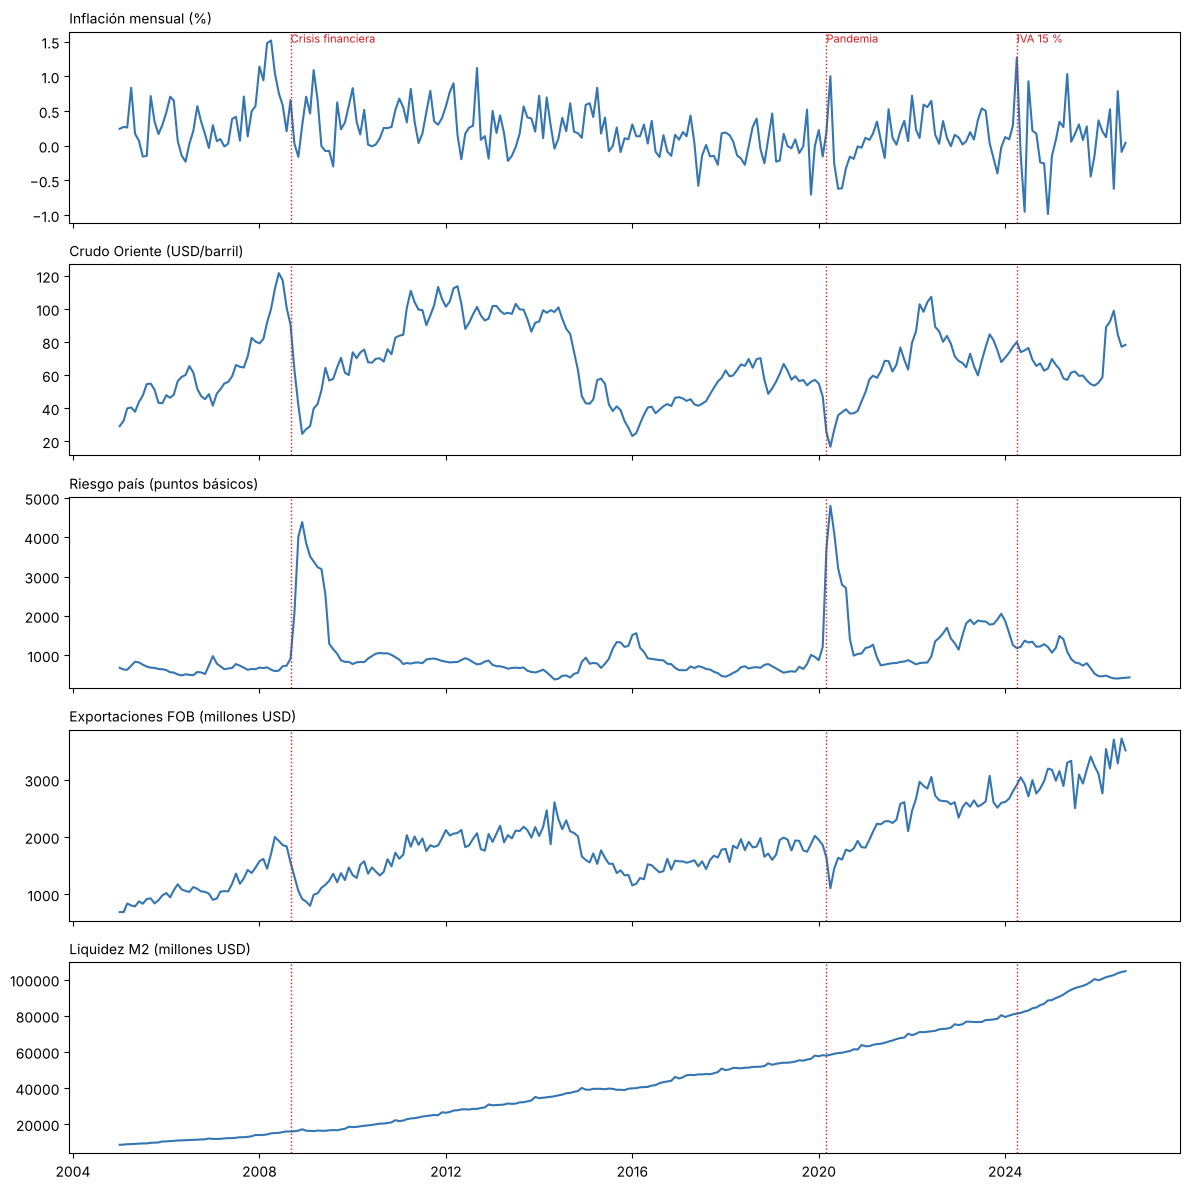

In [18]:
eventos = {'2008-09-01': 'Crisis financiera', '2020-03-01': 'Pandemia', '2024-04-01': 'IVA 15 %'}

paneles = [
    ('ipc_var_mensual', 'Inflación mensual (%)'),
    ('precio_crudo_oriente_usd', 'Crudo Oriente (USD/barril)'),
    ('riesgo_pais_pb', 'Riesgo país (puntos básicos)'),
    ('exportaciones_fob_musd', 'Exportaciones FOB (millones USD)'),
    ('liquidez_m2_musd', 'Liquidez M2 (millones USD)'),
]

fig, axes = plt.subplots(len(paneles), 1, figsize=(12, 12), sharex=True)
for ax, (col, titulo) in zip(axes, paneles):
    ax.plot(series[col].loc['2005':], color='#3476B1')
    ax.set_title(titulo, loc='left', fontsize=10)
    for fecha, nombre in eventos.items():
        ax.axvline(pd.Timestamp(fecha), color='#DA181E', linestyle=':', linewidth=1)
for fecha, nombre in eventos.items():
    axes[0].text(pd.Timestamp(fecha), axes[0].get_ylim()[1], nombre, color='#DA181E', fontsize=8, va='top')
plt.tight_layout()
plt.show()

### Lectura

- **2008:** el crudo llega a ≈ 122 USD en junio y luego se desploma; el riesgo país se dispara hasta ≈ 4 400 puntos en diciembre (moratoria de la deuda externa) y la inflación, que venía alta, empieza a bajar.
- **2020:** el crudo cae a ≈ 17 USD por barril en abril, el riesgo país promedia ≈ 4 800 puntos ese mes y las exportaciones caen. La inflación sube en abril y luego tiene varios meses de **deflación**.
- **2024:** el IVA se ve en la inflación de abril; los demás indicadores no muestran un quiebre en ese mes.
- La **M2** crece de forma sostenida: por eso la usamos en variación anual.

Los grandes eventos mueven **varias series a la vez**. Esto es lo que intenta capturar un VAR (Día 3) y, de forma más simple, lo que hicimos al agregar variables macro.

# 8. Cambios estructurales (4.3)

## 8.1 ¿Qué es un cambio estructural?

Un **cambio estructural** es un momento a partir del cual la serie **se comporta de otra manera**: cambia su media, su varianza o su relación con el pasado. Ocurre cuando cambian las reglas de la economía: un nuevo régimen monetario, una crisis profunda, un cambio permanente de impuestos.

**Por qué importa al pronosticar:** todos los modelos del módulo suponen que el pasado es una guía del futuro (estacionariedad, Día 2). Si en los datos de entrenamiento hay **dos economías distintas**, el modelo aprende un promedio de ambas que no describe ninguna.

| Tipo | Qué cambia | Ejemplo en Ecuador |
|---|---|---|
| Cambio de nivel permanente | la media | **dolarización** (2000) |
| Choque transitorio | unos meses distintos, luego vuelve | **pandemia** (2020) |
| Choque puntual | un solo mes | **IVA** (abril 2024) |

## 8.2 La dolarización: un cambio de nivel

**Qué vamos a hacer:** mirar la inflación mensual desde 1990 y comparar su media antes y después.

In [19]:
y_larga = series['ipc_var_mensual'].loc['1990':].dropna()

etapas = {
    '1990–1999 (sucre)': ('1990', '1999'),
    '2000 (transición)': ('2000', '2000'),
    '2001–2004 (ajuste)': ('2001', '2004'),
    '2005–2026 (dolarización consolidada)': ('2005', '2026'),
}

resumen_etapas = pd.DataFrame({
    nombre: {'media': y_larga.loc[a:b].mean(), 'desviacion': y_larga.loc[a:b].std(), 'meses': y_larga.loc[a:b].count()}
    for nombre, (a, b) in etapas.items()
}).T
resumen_etapas.round(2)

,media,desviacion,meses
1990–1999 (sucre),2.81,1.86,120.0
2000 (transición),5.61,4.08,12.0
2001–2004 (ajuste),0.78,1.18,48.0
2005–2026 (dolarización consolidada),0.21,0.37,260.0


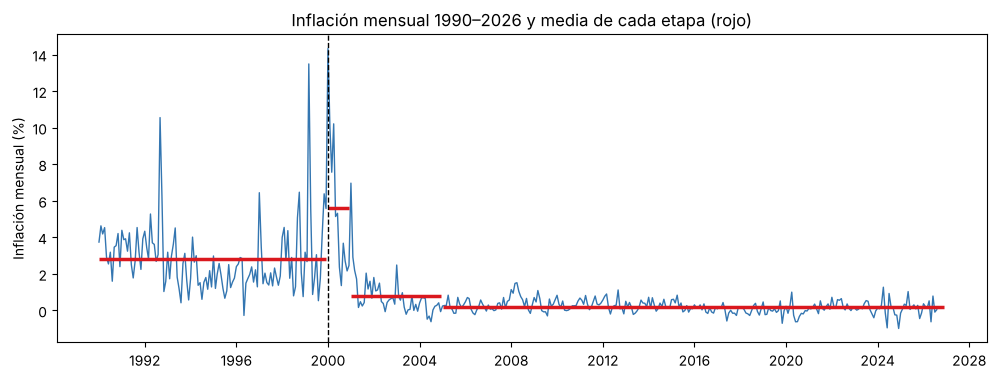

In [20]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_larga, color='#3476B1', linewidth=1)
for nombre, (a, b) in etapas.items():
    media = y_larga.loc[a:b].mean()
    ax.hlines(media, pd.Timestamp(f'{a}-01-01'), pd.Timestamp(f'{b}-12-01'), color='#DA181E', linewidth=2.5)
ax.axvline(pd.Timestamp('2000-01-01'), color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Inflación mensual (%)')
ax.set_title('Inflación mensual 1990–2026 y media de cada etapa (rojo)')
plt.show()

**Lectura:** la inflación mensual media pasó de ≈ 2.8 % (sucre) a ≈ 5.6 % en el año 2000 y a ≈ 0.21 % en la dolarización consolidada: **trece veces menor**. La dispersión también cambió. Son dos economías distintas.

### Medirlo con una regresión: variable de cambio de nivel

Una forma formal de estimar el cambio es una regresión con una variable que vale 0 antes de 2001 y 1 desde 2001:

$$
y_t = \beta_0 + \beta_1\, D_t + \varepsilon_t \qquad D_t = \begin{cases} 0 & t < 2001 \\ 1 & t \geq 2001 \end{cases}
$$

- $\beta_0$ es la media **antes** de 2001;
- $\beta_0 + \beta_1$ es la media **después**;
- $\beta_1$ es el **tamaño del cambio**, y su p-valor dice si es significativo.

**A mano:** $\beta_0$ = media de 1990–2000 y $\beta_1$ = media de 2001–2026 menos media de 1990–2000.

`OLS` de statsmodels (Módulo 3, Día 1) sigue el patrón **crear → `fit()` → consultar**; `sm.add_constant` agrega la columna de unos para $\beta_0$.

In [21]:
D = (y_larga.index >= '2001-01-01').astype(int)
regresion = sm.OLS(y_larga, sm.add_constant(pd.Series(D, index=y_larga.index, name='desde_2001'))).fit()

print('A mano · media antes:', round(y_larga.loc[:'2000'].mean(), 3), '· media después:', round(y_larga.loc['2001':].mean(), 3))
print(regresion.summary().tables[1])

A mano · media antes: 3.063 · media después: 0.301
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0626      0.117     26.143      0.000       2.832       3.293
desde_2001    -2.7618      0.140    -19.725      0.000      -3.037      -2.487


**Lectura:** $\beta_0 \approx 3.06$ (media antes de 2001) y $\beta_1 \approx -2.76$ (la media cae casi 2.8 puntos), con p-valor ≈ 0: **el cambio es estadísticamente indiscutible**. Coincide con el cálculo a mano.

## 8.3 Consecuencia práctica: ¿desde qué año entrenar?

**Qué vamos a hacer:** estimar el mismo ARIMA(1,0,0) empezando en distintos años y medir su error en el Test.

In [22]:
filas = []
for inicio in ['1990', '2001', '2005', '2010', '2015']:
    r = ARIMA(y_larga.loc[inicio:'2024-12'], order=(1, 0, 0), trend='c').fit()
    pred = r.apply(y_larga.loc[inicio:]).predict(start='2025-01-01', end='2026-08-01')
    filas.append({
        'inicio_entrenamiento': inicio,
        'meses_entrenamiento': int(r.nobs),
        'media_estimada': r.params['const'],
        'phi': r.params['ar.L1'],
        'MAE_Test': mean_absolute_error(y_larga.loc['2025-01':'2026-08'], pred),
    })

pd.DataFrame(filas).set_index('inicio_entrenamiento').round(3)

,meses_entrenamiento,media_estimada,phi,MAE_Test
inicio_entrenamiento,,,,
1990,420,1.178,0.731,0.433
2001,288,0.366,0.753,0.392
2005,240,0.213,0.423,0.307
2010,180,0.165,0.296,0.284
2015,120,0.091,0.220,0.281


### Lectura

| Inicio | Media estimada | MAE Test | Por qué |
|---|---:|---:|---|
| 1990 | ≈ 1.18 % | ≈ 0.43 | aprende la economía del sucre: pronostica inflación muy alta |
| 2001 | ≈ 0.37 % | ≈ 0.39 | incluye el ajuste post dolarización |
| 2005 | ≈ 0.21 % | ≈ 0.31 | la elección del Día 1 |
| 2015 | ≈ 0.09 % | ≈ 0.28 | la economía más reciente, con menos datos |

**Más datos no siempre es mejor.** Entrenar con 1990 da 420 meses pero el peor pronóstico. Empezar en 2015 da el mejor Test, pero con solo 120 meses los parámetros son menos precisos y el periodo no incluye una inflación alta como la de 2008 o 2022. **La elección del periodo es un balance entre cantidad de datos y parecido con el presente**, y hay que justificarla con argumentos económicos, no solo con el Test.

## 8.4 La pandemia: un choque transitorio

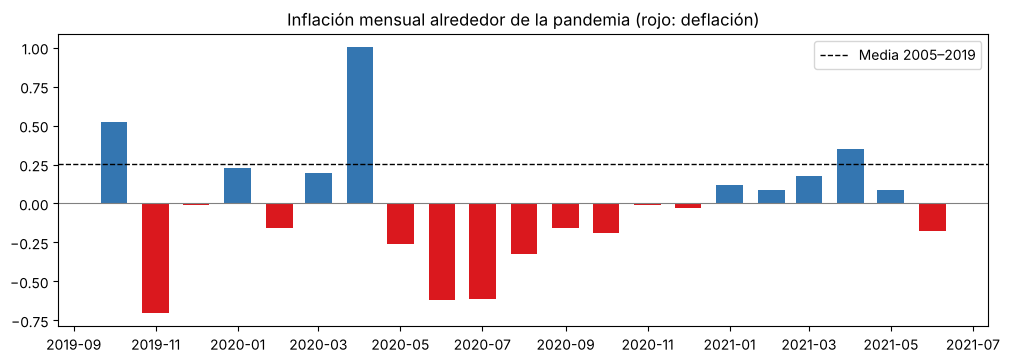

Meses con deflación entre mayo y diciembre de 2020: 8 de 8


In [23]:
pandemia = y.loc['2019-10':'2021-06']

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(pandemia.index, pandemia, width=20, color=['#DA181E' if v < 0 else '#3476B1' for v in pandemia])
ax.axhline(y.loc[:'2019-12'].mean(), color='black', linestyle='--', linewidth=1, label='Media 2005–2019')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Inflación mensual alrededor de la pandemia (rojo: deflación)')
ax.legend()
plt.show()

print('Meses con deflación entre mayo y diciembre de 2020:', int((y.loc['2020-05':'2020-12'] < 0).sum()), 'de 8')

**Lectura:** en abril de 2020 la inflación sube a 1.0 % (compras de pánico al inicio del confinamiento) y de mayo a diciembre de 2020 **todos** los meses tienen deflación, por la caída de la demanda. Desde 2021 la inflación vuelve gradualmente a valores positivos.

A diferencia de la dolarización, la pandemia **no cambió el nivel de largo plazo**: es un **choque transitorio**. Las opciones para tratarlo son las del Día 1 (marcar con una variable de intervención, usar métodos robustos) o simplemente reconocer que en esos meses ningún modelo basado en el pasado podía acertar.

## 8.5 El IVA de 2024: un choque puntual

Lo trabajamos el Día 3 con una variable de intervención: el modelo atribuyó ≈ 1.1 puntos de inflación a abril de 2024. Es el tercer tipo de cambio: **un solo mes**, con un efecto claro y una causa documentada.

### Resumen: qué hacer con cada tipo de cambio

| Tipo | Ejemplo | Qué hacer |
|---|---|---|
| Cambio de nivel permanente | dolarización | **elegir el periodo** de entrenamiento posterior al cambio, o modelar el quiebre |
| Choque transitorio | pandemia | variable de intervención para los meses afectados, métodos robustos o aceptarlo como error |
| Choque puntual | IVA | variable de intervención de un mes |

# 9. Comparación final de todos los modelos

**Qué vamos a hacer:** reunir en una sola tabla los modelos del módulo y los de hoy, ordenados por MAE en el Test.

In [24]:
tabla_final = tabla_promedios.copy()
tabla_final.loc['SARIMA(1,0,0)(1,0,0)12 (Día 3)', 'Test'] = 0.374
tabla_final.loc['Ingenuo (Día 1)', 'Test'] = 0.478
tabla_final.sort_values('Test').round(3)

,Validación,Test
RF + macro,0.272,0.272
Promedio de los 3 (con RF + macro),0.252,0.280
Promedio de los 3,0.255,0.284
Promedio móvil 12,0.248,0.286
Promedio ARIMA + PM12,0.250,0.287
Híbrido ARIMA + RF residuos,0.268,0.292
Híbrido ARIMA + RF residuos (macro),0.257,0.295
"ARIMA(1,0,0)",0.276,0.307
Random Forest,0.280,0.313
"SARIMA(1,0,0)(1,0,0)12 (Día 3)",NaN,0.374


### Conclusiones del día

1. **Combinar modelos** que usan la misma información mejora poco, porque sus errores están muy correlacionados.
2. **El híbrido ARIMA + RF sobre residuos** mejora a ARIMA solo, pero no al promedio móvil.
3. **Las variables macro** dieron el mejor Test (≈ 0.272), pero la validación no lo confirmó: es una señal prometedora, no una conclusión.
4. **Elegir el periodo de entrenamiento** cambia más el resultado que elegir el modelo: entrenar desde 1990 aumenta el error del Test en más de 50 % frente a entrenar desde 2015.

En términos del Día 6: el pronóstico **base** podría ser el promedio de los 3 modelos con RF + macro, y el **rango** de los modelos nos da una primera idea de la incertidumbre.

# 10. Actividad 3 · ¿Qué modelo elegirías? (20 puntos)

**Trabajo individual · 30–40 minutos · sin entrenar modelos.** El docente entregará una tabla con los resultados de tres métodos (ingenuo, ARIMA y Random Forest) aplicados a una misma serie. Debes:

1. interpretar MAE y RMSE en la unidad de la serie;
2. identificar el modelo con menor error **según cada métrica** (pueden no coincidir);
3. recomendar uno para un informe económico, considerando precisión, simplicidad y facilidad de explicación;
4. describir una situación concreta en la que incluso el mejor modelo podría fallar (piensa en la parte 8).

Entrega: una página. La rúbrica está en el instrumento de evaluación.

# 11. Reto de cierre

1. Repite la selección de variables (parte 5) agregando `riesgo_var_mensual` y `reservas_var_anual` con su mejor rezago. ¿Mejora la validación del RF?
2. Construye un **promedio ponderado**: da más peso al modelo con menor MAE en validación (por ejemplo, pesos inversamente proporcionales al MAE). ¿Supera al promedio simple en el Test?
3. Estima el ARIMA(1,0,0) desde 2005 con una variable de intervención para **mayo a diciembre de 2020**. ¿Cuánto vale su coeficiente y qué significa?
4. Escribe un párrafo para un público no técnico explicando por qué el modelo no se entrena con datos de antes de 2001.

In [25]:
# A partir de aquí escribe tus propias celdas.

## Checklist del día

- [ ] ¿Comparé modelos combinados contra sus piezas, en Validación **y** en Test?
- [ ] ¿Revisé la correlación entre los errores de los modelos antes de promediarlos?
- [ ] ¿Transformé cada indicador a una escala estacionaria y lo rezagué al menos un mes?
- [ ] ¿Excluí variables que contienen la respuesta por construcción?
- [ ] ¿Elegí las variables con datos hasta 2024, sin mirar el Test?
- [ ] ¿Revisé si mi periodo de entrenamiento mezcla economías distintas?
- [ ] ¿Reporté una mejora en el Test sin exagerarla cuando la validación no la confirmó?

**Puente hacia el Día 6:** ya tenemos varios modelos y una idea de su precisión. Mañana mediremos su error en muchos orígenes (**backtesting**), construiremos **escenarios** optimista, base y pesimista, y prepararemos un **script de actualización** de datos para el proyecto final.